# Artificial Neural Network (ANN) for Binary Classification
This notebook demonstrates how to build, train, and evaluate a simple feedforward neural network (Multi-Layer Perceptron) using **PyTorch** on the **make_moons** dataset from Scikit-learn.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim

np.random.seed(42)
torch.manual_seed(42)

## 1. Generate and Visualize the Dataset

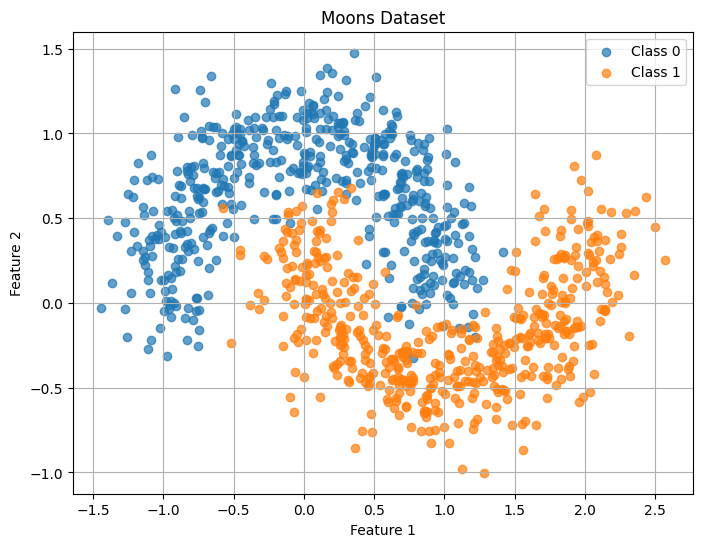

In [11]:
X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], label='Class 0', alpha=0.7)
plt.scatter(X[y == 1, 0], X[y == 1, 1], label='Class 1', alpha=0.7)
plt.title("Moons Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

## 2. Define the ANN Model

In [12]:
X_train_t = torch.FloatTensor(X_train)
y_train_t = torch.FloatTensor(y_train).view(-1, 1)
X_test_t = torch.FloatTensor(X_test)
y_test_t = torch.FloatTensor(y_test).view(-1, 1)

class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)

model = MLP()
print(model)

MLP(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
    (5): Sigmoid()
  )
)


## 3. Train the Model

Epoch 025 | Train Loss: 0.3679 | Test Accuracy: 0.8200
Epoch 050 | Train Loss: 0.2822 | Test Accuracy: 0.8750
Epoch 075 | Train Loss: 0.2523 | Test Accuracy: 0.8850
Epoch 100 | Train Loss: 0.1913 | Test Accuracy: 0.9250
Epoch 125 | Train Loss: 0.1216 | Test Accuracy: 0.9750
Epoch 150 | Train Loss: 0.0927 | Test Accuracy: 0.9800


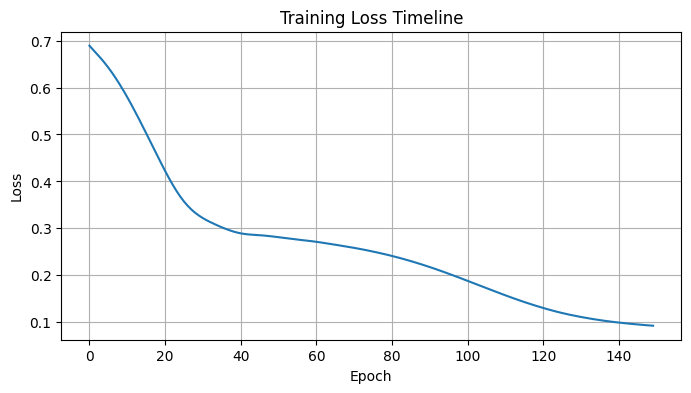

In [13]:
X_train_t = torch.FloatTensor(X_train)
y_train_t = torch.FloatTensor(y_train).view(-1, 1)
X_test_t = torch.FloatTensor(X_test)
y_test_t = torch.FloatTensor(y_test).view(-1, 1)

if 'model' not in globals():
    model = MLP()

criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

epochs = 150
loss_history = []

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    predictions = model(X_train_t)
    loss = criterion(predictions, y_train_t)

    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 25 == 0:
        model.eval()
        with torch.no_grad():
            test_preds = model(X_test_t)
            test_preds_class = (test_preds >= 0.5).float()
            accuracy = (test_preds_class == y_test_t).float().mean()
        print(f"Epoch {epoch+1:03d} | Train Loss: {loss.item():.4f} | Test Accuracy: {accuracy.item():.4f}")

plt.figure(figsize=(8, 4))
plt.plot(loss_history, label='Loss')
plt.title('Training Loss Timeline')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.show()

## 4. Visualize Decision Boundary

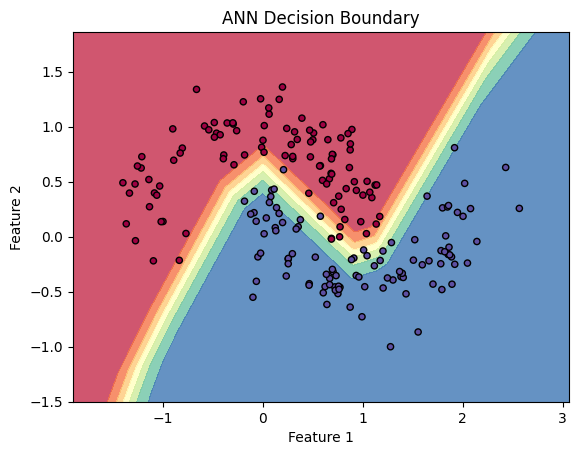

In [14]:
def plot_decision_boundary(model, X, y):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))

    grid_tensor = torch.FloatTensor(np.c_[xx.ravel(), yy.ravel()])

    model.eval()
    with torch.no_grad():
        preds = model(grid_tensor).reshape(xx.shape).numpy()

    plt.contourf(xx, yy, preds, cmap=plt.cm.Spectral, alpha=0.8)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Spectral, edgecolors='black', s=20)
    plt.title("ANN Decision Boundary")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

target_model = globals().get('model', None)
if target_model is None:
    target_model = MLP()

plot_decision_boundary(target_model, X_test, y_test)